In [16]:

# Import standard libraries for file handling and configuration.
import os
import json
import random
import shutil
import zipfile
from pathlib import Path


# Import numerical and data-processing libraries.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Import PyTorch for the trained Residual MLP.
import torch
import torch.nn as nn
from datasets import load_dataset

# Import Sentence-BERT for 384-dimensional prompt embeddings.
from sentence_transformers import SentenceTransformer

# Select the available device for inference.
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("All libraries imported successfully!")
print("PyTorch version:", torch.__version__)
print("Execution device:", DEVICE)


All libraries imported successfully!
PyTorch version: 2.11.0+cu130
Execution device: cuda


In [7]:
from huggingface_hub import hf_hub_download


# Download one of the pickle files (e.g., routerbench_0shot.pkl)
filepath = hf_hub_download(repo_id="withmartian/routerbench",
    filename="routerbench_0shot.pkl",
    repo_type="dataset")

# Load the dataset using pandas
df = pd.read_pickle(filepath)
print("Dataset shape:", df.shape)
print(df.head())

routerbench_0shot.pkl: reconstructing file:   0%|          |  0.00B / 99.6MB            

routerbench_0shot.pkl: downloading bytes:           |  0.00B            

Dataset shape: (36497, 37)
                          sample_id  \
0   Chinese_character_riddles.dev.0   
1   Chinese_character_riddles.dev.1   
2  Chinese_character_riddles.dev.10   
3  Chinese_character_riddles.dev.11   
4  Chinese_character_riddles.dev.12   

                                              prompt  \
0  ['猜字谜，根据我给的描述猜出一个字(请从汉字的字形、发音、意义以及字的拆分组合等角度考虑)...   
1  ['猜字谜，根据我给的描述猜出一个字(请从汉字的字形、发音、意义以及字的拆分组合等角度考虑)...   
2  ['猜字谜，根据我给的描述猜出一个字(请从汉字的字形、发音、意义以及字的拆分组合等角度考虑)...   
3  ['猜字谜，根据我给的描述猜出一个字(请从汉字的字形、发音、意义以及字的拆分组合等角度考虑)...   
4  ['猜字谜，根据我给的描述猜出一个字(请从汉字的字形、发音、意义以及字的拆分组合等角度考虑)...   

                   eval_name WizardLM/WizardLM-13B-V1.2 claude-instant-v1  \
0  Chinese_character_riddles                        0.0               0.0   
1  Chinese_character_riddles                        0.0               0.0   
2  Chinese_character_riddles                        0.0               0.0   
3  Chinese_character_riddles                        0.0               0.0   
4  Chinese_chara

In [8]:
# Identify quality columns, excluding cost and metadata columns.
model_columns = [column for column in df.columns if "|total_cost" not in column and column not in ["sample_id", "prompt", "eval_name"]]

# Identify columns containing total costs.
cost_columns = [column for column in df.columns if "|total_cost" in column]

# Display the number and names of quality and cost columns.
print("Quality columns:", len(model_columns))
print(model_columns)
print("\nCost columns:", len(cost_columns))
print(cost_columns)

Quality columns: 23
['WizardLM/WizardLM-13B-V1.2', 'claude-instant-v1', 'claude-v1', 'claude-v2', 'gpt-3.5-turbo-1106', 'gpt-4-1106-preview', 'meta/code-llama-instruct-34b-chat', 'meta/llama-2-70b-chat', 'mistralai/mistral-7b-chat', 'mistralai/mixtral-8x7b-chat', 'zero-one-ai/Yi-34B-Chat', 'gpt-3.5-turbo-1106|model_response', 'claude-instant-v1|model_response', 'claude-v1|model_response', 'claude-v2|model_response', 'gpt-4-1106-preview|model_response', 'meta/llama-2-70b-chat|model_response', 'mistralai/mixtral-8x7b-chat|model_response', 'zero-one-ai/Yi-34B-Chat|model_response', 'WizardLM/WizardLM-13B-V1.2|model_response', 'meta/code-llama-instruct-34b-chat|model_response', 'mistralai/mistral-7b-chat|model_response', 'oracle_model_to_route_to']

Cost columns: 11
['gpt-3.5-turbo-1106|total_cost', 'claude-instant-v1|total_cost', 'claude-v1|total_cost', 'claude-v2|total_cost', 'gpt-4-1106-preview|total_cost', 'meta/llama-2-70b-chat|total_cost', 'mistralai/mixtral-8x7b-chat|total_cost', 'ze

In [9]:
print("Unique benchmarks:", df["eval_name"].nunique())
print("Unique benchmarks:")
print(df["eval_name"].value_counts())

Unique benchmarks: 86
Unique benchmarks:
eval_name
hellaswag                    10042
grade-school-math             7450
mmlu-professional-law         1534
arc-challenge                 1470
winogrande                    1267
                             ...  
chinese_idioms                  15
chinese_poem                    15
chinese-remainder-theorem       15
chinese_chu_ci                  15
test-match                       3
Name: count, Length: 86, dtype: int64


In [10]:
# Define metadata columns that do not contain model quality scores.
meta_columns = ["sample_id", "prompt", "eval_name"]

# Identify columns containing total costs for each model.
cost_columns = [column for column in df.columns if column.endswith("|total_cost")]

# Identify quality columns by excluding metadata and cost columns.
quality_columns = [column for column in df.columns if column not in meta_columns and column not in cost_columns]

# Display the number and names of quality and cost columns.
print("Quality columns:", len(quality_columns))
print("Cost columns:", len(cost_columns))
print("Quality models:", quality_columns)
print("Cost models:", [column.replace("|total_cost", "") for column in cost_columns])

Quality columns: 23
Cost columns: 11
Quality models: ['WizardLM/WizardLM-13B-V1.2', 'claude-instant-v1', 'claude-v1', 'claude-v2', 'gpt-3.5-turbo-1106', 'gpt-4-1106-preview', 'meta/code-llama-instruct-34b-chat', 'meta/llama-2-70b-chat', 'mistralai/mistral-7b-chat', 'mistralai/mixtral-8x7b-chat', 'zero-one-ai/Yi-34B-Chat', 'gpt-3.5-turbo-1106|model_response', 'claude-instant-v1|model_response', 'claude-v1|model_response', 'claude-v2|model_response', 'gpt-4-1106-preview|model_response', 'meta/llama-2-70b-chat|model_response', 'mistralai/mixtral-8x7b-chat|model_response', 'zero-one-ai/Yi-34B-Chat|model_response', 'WizardLM/WizardLM-13B-V1.2|model_response', 'meta/code-llama-instruct-34b-chat|model_response', 'mistralai/mistral-7b-chat|model_response', 'oracle_model_to_route_to']
Cost models: ['gpt-3.5-turbo-1106', 'claude-instant-v1', 'claude-v1', 'claude-v2', 'gpt-4-1106-preview', 'meta/llama-2-70b-chat', 'mistralai/mixtral-8x7b-chat', 'zero-one-ai/Yi-34B-Chat', 'WizardLM/WizardLM-13B-V1

In [11]:
# Extract model names from the quality and cost columns.
quality_models = set(quality_columns)
cost_models = {column.replace("|total_cost", "") for column in cost_columns}

# Keep only models that have both quality scores and cost data.
models = sorted(quality_models.intersection(cost_models))

# Display the candidate models available for routing.
print("Models available for routing:", len(models))
print(models)

Models available for routing: 11
['WizardLM/WizardLM-13B-V1.2', 'claude-instant-v1', 'claude-v1', 'claude-v2', 'gpt-3.5-turbo-1106', 'gpt-4-1106-preview', 'meta/code-llama-instruct-34b-chat', 'meta/llama-2-70b-chat', 'mistralai/mistral-7b-chat', 'mistralai/mixtral-8x7b-chat', 'zero-one-ai/Yi-34B-Chat']


In [12]:
# Extract model quality scores into a numerical matrix.
quality_matrix = df[models].apply(pd.to_numeric, errors="coerce")

# Extract the corresponding total-cost columns and align their names with the model names.
cost_matrix = df[[f"{model}|total_cost" for model in models]].copy()
cost_matrix.columns = models

# Convert cost values to numeric, replacing invalid values with NaN.
cost_matrix = cost_matrix.apply(pd.to_numeric, errors="coerce")

# Display the dimensions of both matrices.
print("Quality matrix:", quality_matrix.shape)
print("Cost matrix:", cost_matrix.shape)

Quality matrix: (36497, 11)
Cost matrix: (36497, 11)


In [13]:
print("Quality missing values:", quality_matrix.isna().sum().sum())
print("Cost missing values:", cost_matrix.isna().sum().sum())

Quality missing values: 0
Cost missing values: 0


In [14]:
model_summary = pd.DataFrame({"mean_quality": quality_matrix.mean(), "mean_cost": cost_matrix.mean(), "median_cost": cost_matrix.median()}).sort_values("mean_cost")
model_summary

,mean_quality,mean_cost,median_cost
mistralai/mistral-7b-chat,0.306111,0.000046,0.000037
WizardLM/WizardLM-13B-V1.2,0.431127,0.000073,0.000056
mistralai/mixtral-8x7b-chat,0.547115,0.000135,0.000113
meta/code-llama-instruct-34b-chat,0.202228,0.000172,0.000140
zero-one-ai/Yi-34B-Chat,0.647492,0.000186,0.000148
meta/llama-2-70b-chat,0.328689,0.000203,0.000172
claude-instant-v1,0.598414,0.000233,0.000152
gpt-3.5-turbo-1106,0.619321,0.000243,0.000188
claude-v1,0.630118,0.002145,0.001528
claude-v2,0.635806,0.002419,0.001560


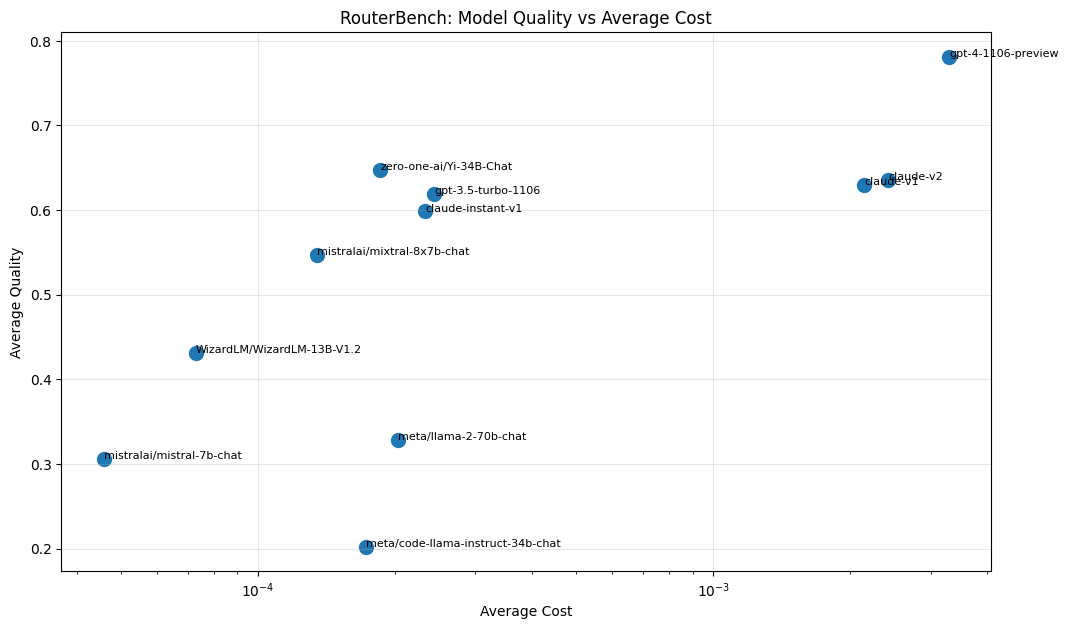

In [17]:
# Plot average model quality against average cost.
plt.figure(figsize=(12, 7))
plt.scatter(model_summary["mean_cost"], model_summary["mean_quality"], s=100)

# Annotate each point with its model name.
for model in model_summary.index:
    plt.annotate(model, (model_summary.loc[model, "mean_cost"], model_summary.loc[model, "mean_quality"]), fontsize=8)

# Add labels, a title and a logarithmic cost scale.
plt.xlabel("Average Cost")
plt.ylabel("Average Quality")
plt.title("RouterBench: Model Quality vs Average Cost")
plt.xscale("log")
plt.grid(alpha=0.3)
plt.show()

In [18]:
cheapest_model = model_summary["mean_cost"].idxmin()
print("Cheapest model:", cheapest_model)
print("Average cost:", model_summary.loc[cheapest_model, "mean_cost"])

Cheapest model: mistralai/mistral-7b-chat
Average cost: 4.572428966764392e-05


In [19]:
strongest_model = model_summary["mean_quality"].idxmax()
print("Strongest model:", strongest_model)
print("Average quality:", model_summary.loc[strongest_model, "mean_quality"])

Strongest model: gpt-4-1106-preview
Average quality: 0.7813998410828287


In [20]:
df["oracle_model"] = quality_matrix.idxmax(axis=1)
df["oracle_quality"] = quality_matrix.max(axis=1)
df["oracle_cost"] = cost_matrix.lookup(df.index, df["oracle_model"]) if hasattr(cost_matrix, "lookup") else np.array([cost_matrix.loc[index, model] for index, model in zip(df.index, df["oracle_model"])])

In [21]:
oracle_distribution = df["oracle_model"].value_counts()
oracle_distribution


,count
oracle_model,
WizardLM/WizardLM-13B-V1.2,16335
claude-instant-v1,10995
claude-v1,2926
gpt-4-1106-preview,1803
claude-v2,1746
gpt-3.5-turbo-1106,1574
mistralai/mistral-7b-chat,394
zero-one-ai/Yi-34B-Chat,260
mistralai/mixtral-8x7b-chat,221


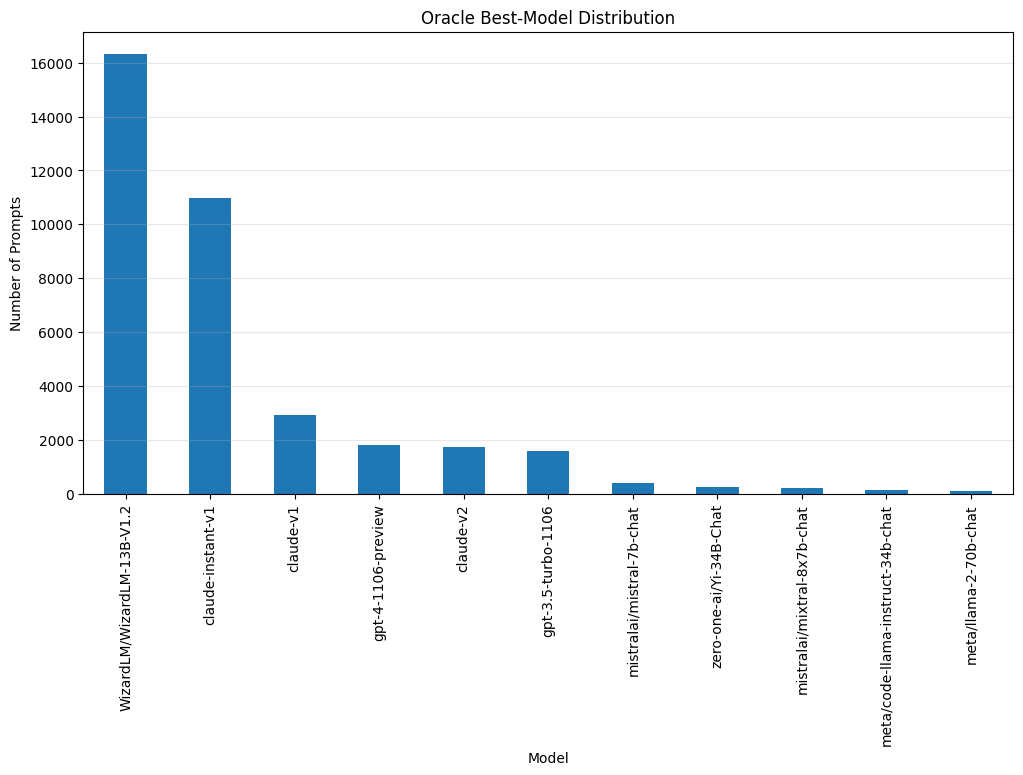

In [22]:
# Plot the number of prompts for which each model is the oracle's best choice.
plt.figure(figsize=(12, 6))
oracle_distribution.plot(kind="bar")

# Add axis labels and a descriptive title.
plt.xlabel("Model")
plt.ylabel("Number of Prompts")
plt.title("Oracle Best-Model Distribution")

# Rotate model names for better readability.
plt.xticks(rotation=90)

# Add horizontal grid lines to make comparisons easier.
plt.grid(axis="y", alpha=0.3)
plt.show()

In [23]:
df["best_model"] = quality_matrix.idxmax(axis=1)
df["best_quality"] = quality_matrix.max(axis=1)

In [24]:
target_distribution = df["best_model"].value_counts()
display(target_distribution)

,count
best_model,
WizardLM/WizardLM-13B-V1.2,16335
claude-instant-v1,10995
claude-v1,2926
gpt-4-1106-preview,1803
claude-v2,1746
gpt-3.5-turbo-1106,1574
mistralai/mistral-7b-chat,394
zero-one-ai/Yi-34B-Chat,260
mistralai/mixtral-8x7b-chat,221


In [25]:
valid_rows = df["best_quality"].notna()
df = df.loc[valid_rows].reset_index(drop=True)
quality_matrix = quality_matrix.loc[valid_rows].reset_index(drop=True)
cost_matrix = cost_matrix.loc[valid_rows].reset_index(drop=True)
print("Valid samples:", len(df))

Valid samples: 36497


In [26]:
print("Number of routing classes:", df["best_model"].nunique())
print(df["best_model"].value_counts())

Number of routing classes: 11
best_model
WizardLM/WizardLM-13B-V1.2           16335
claude-instant-v1                    10995
claude-v1                             2926
gpt-4-1106-preview                    1803
claude-v2                             1746
gpt-3.5-turbo-1106                    1574
mistralai/mistral-7b-chat              394
zero-one-ai/Yi-34B-Chat                260
mistralai/mixtral-8x7b-chat            221
meta/code-llama-instruct-34b-chat      153
meta/llama-2-70b-chat                   90
Name: count, dtype: int64


In [27]:
class_counts = df["best_model"].value_counts()
imbalance_ratio = class_counts.max() / class_counts.min()
print(f"Total samples: {len(df)}")
print(f"Number of classes: {df['best_model'].nunique()}")
print(f"Majority class: {class_counts.index[0]}")
print(f"Majority samples: {class_counts.iloc[0]}")
print(f"Minority class: {class_counts.index[-1]}")
print(f"Minority samples: {class_counts.iloc[-1]}")
print(f"Imbalance ratio: {imbalance_ratio:.2f}:1")

Total samples: 36497
Number of classes: 11
Majority class: WizardLM/WizardLM-13B-V1.2
Majority samples: 16335
Minority class: meta/llama-2-70b-chat
Minority samples: 90
Imbalance ratio: 181.50:1


In [28]:

# Keep prompts and quality/cost matrices aligned.
valid_mask = df["prompt"].notna() & quality_matrix.notna().any(axis=1) & cost_matrix.notna().any(axis=1)
clean_prompt = df.loc[valid_mask, "prompt"].astype(str).str.strip().tolist()
quality_matrix = quality_matrix.loc[valid_mask].reset_index(drop=True)
cost_matrix = cost_matrix.loc[valid_mask].reset_index(drop=True)

# Convert quality scores to a numerical array.
quality_values = quality_matrix.to_numpy(dtype=np.float32)
cost_values = cost_matrix.to_numpy(dtype=np.float32)

# Create multi-hot labels for every model tied for the highest quality.
row_max = np.nanmax(quality_values, axis=1, keepdims=True)
labels = np.isclose(quality_values, row_max, rtol=1e-5, atol=1e-8).astype(np.float32)

# Calculate positive and negative counts for each model.
positive_counts = labels.sum(axis=0)
negative_counts = len(labels) - positive_counts

# Calculate class weights, handling models with no positive examples.
class_weights = negative_counts / np.maximum(positive_counts, 1)

print("Valid prompts:", len(clean_prompt))
print("Quality matrix:", quality_values.shape)
print("Cost matrix:", cost_values.shape)
print("Labels:", labels.shape)
print("Average positive labels per prompt:", round(float(labels.sum(axis=1).mean()), 3))
print("Class weights:", dict(zip(models, class_weights.round(3))))


Valid prompts: 36497
Quality matrix: (36497, 11)
Cost matrix: (36497, 11)
Labels: (36497, 11)
Average positive labels per prompt: 6.043
Class weights: {'WizardLM/WizardLM-13B-V1.2': np.float32(1.234), 'claude-instant-v1': np.float32(0.546), 'claude-v1': np.float32(0.468), 'claude-v2': np.float32(0.461), 'gpt-3.5-turbo-1106': np.float32(0.539), 'gpt-4-1106-preview': np.float32(0.221), 'meta/code-llama-instruct-34b-chat': np.float32(3.696), 'meta/llama-2-70b-chat': np.float32(1.859), 'mistralai/mistral-7b-chat': np.float32(2.206), 'mistralai/mixtral-8x7b-chat': np.float32(0.763), 'zero-one-ai/Yi-34B-Chat': np.float32(0.486)}


In [29]:
embedding_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=str(DEVICE))

# Convert prompts into embeddings in batches.
prompt_embeddings = embedding_model.encode(clean_prompt, batch_size=64, show_progress_bar=True, convert_to_numpy=True, normalize_embeddings=False).astype(np.float32)

print("Prompt embeddings:", prompt_embeddings.shape)


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/571 [00:00<?, ?it/s]

Prompt embeddings: (36497, 384)


In [32]:
# Count how many prompts each model achieves the highest quality on.
positive_counts = labels.sum(axis=0)

# Count prompts where each model is not among the best-quality models.
negative_counts = len(labels) - positive_counts

# Calculate the positive class weight for each model.
class_weights = negative_counts / np.maximum(positive_counts, 1)

# Display the calculated weights for each candidate model.
class_weight_df = pd.DataFrame({"Model": models, "Positive Count": positive_counts.astype(int), "Negative Count": negative_counts.astype(int), "Class Weight": class_weights})
display(class_weight_df.sort_values("Class Weight", ascending=False).reset_index(drop=True))

,Model,Positive Count,Negative Count,Class Weight
0,meta/code-llama-instruct-34b-chat,7772,28725,3.695960
1,mistralai/mistral-7b-chat,11385,25112,2.205709
2,meta/llama-2-70b-chat,12767,23730,1.858698
3,WizardLM/WizardLM-13B-V1.2,16335,20162,1.234282
4,mistralai/mixtral-8x7b-chat,20706,15791,0.762629
5,claude-instant-v1,23601,12896,0.546418
6,gpt-3.5-turbo-1106,23718,12779,0.538789
7,zero-one-ai/Yi-34B-Chat,24567,11930,0.485611
8,claude-v1,24860,11637,0.468101
9,claude-v2,24974,11523,0.461400


In [33]:
from sklearn.model_selection import train_test_split

# Use a single best-model label for stratification only.
stratify_labels = labels.argmax(axis=1)
indices = np.arange(len(labels))

# Reserve 30% for final testing.
train_val_idx, test_idx = train_test_split(indices, test_size=0.30, random_state=42, stratify=stratify_labels)

# Split the remaining data into training and validation sets.
train_idx, val_idx = train_test_split(train_val_idx, test_size=0.20, random_state=42, stratify=stratify_labels[train_val_idx])

# Create the feature and target arrays for each split.
X_train, X_val, X_test = prompt_embeddings[train_idx], prompt_embeddings[val_idx], prompt_embeddings[test_idx]
y_train, y_val, y_test = labels[train_idx], labels[val_idx], labels[test_idx]

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)


Training: (20437, 384) (20437, 11)
Validation: (5110, 384) (5110, 11)
Testing: (10950, 384) (10950, 11)


In [35]:
from torch.utils.data import TensorDataset, DataLoader

# Define a residual block with a skip connection.
class ResidualBlock(nn.Module):
    def __init__(self, hidden_dim=256, dropout=0.2):
        super().__init__()
        self.block = nn.Sequential(nn.Linear(hidden_dim, hidden_dim), nn.LayerNorm(hidden_dim), nn.GELU(), nn.Dropout(dropout), nn.Linear(hidden_dim, hidden_dim), nn.LayerNorm(hidden_dim))
        self.activation = nn.GELU()

    def forward(self, x):
        return self.activation(x + self.block(x))

# Define the Residual MLP router.
class RouteIQNet(nn.Module):
    def __init__(self, input_dim=384, hidden_dim=256, num_models=11):
        super().__init__()
        self.input_layer = nn.Sequential(nn.Linear(input_dim, hidden_dim), nn.LayerNorm(hidden_dim), nn.GELU())
        self.residual_blocks = nn.Sequential(ResidualBlock(hidden_dim), ResidualBlock(hidden_dim), ResidualBlock(hidden_dim))
        self.output_layer = nn.Linear(hidden_dim, num_models)

    def forward(self, x):
        return self.output_layer(self.residual_blocks(self.input_layer(x)))

# Initialise the new model and training tensors.
model = RouteIQNet(input_dim=X_train.shape[1], hidden_dim=256, num_models=len(models)).to(DEVICE)
train_dataset = TensorDataset(torch.tensor(X_train), torch.tensor(y_train))
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)

print(model)
print("Trainable parameters:", sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad))

RouteIQNet(
  (input_layer): Sequential(
    (0): Linear(in_features=384, out_features=256, bias=True)
    (1): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
    (2): GELU(approximate='none')
  )
  (residual_blocks): Sequential(
    (0): ResidualBlock(
      (block): Sequential(
        (0): Linear(in_features=256, out_features=256, bias=True)
        (1): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
        (2): GELU(approximate='none')
        (3): Dropout(p=0.2, inplace=False)
        (4): Linear(in_features=256, out_features=256, bias=True)
        (5): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
      )
      (activation): GELU(approximate='none')
    )
    (1): ResidualBlock(
      (block): Sequential(
        (0): Linear(in_features=256, out_features=256, bias=True)
        (1): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
        (2): GELU(approximate='none')
        (3): Dropout(p=0.2, inplace=False)
        (4): Linear(in_features=256, out_

In [36]:

# Configure class-weighted loss and the optimiser.
positive_weight = torch.tensor(class_weights, dtype=torch.float32, device=DEVICE)
criterion = nn.BCEWithLogitsLoss(pos_weight=positive_weight)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)

X_val_tensor = torch.tensor(X_val, dtype=torch.float32, device=DEVICE)
y_val_tensor = torch.tensor(y_val, dtype=torch.float32, device=DEVICE)

EPOCHS = 50
PATIENCE = 6
best_val_loss = float("inf")
patience_counter = 0
history = {"train_loss": [], "val_loss": []}
best_state = None

# Train the network and monitor validation loss.
for epoch in range(EPOCHS):
    model.train()
    train_loss_total = 0.0

    for batch_x, batch_y in train_loader:
        batch_x, batch_y = batch_x.to(DEVICE), batch_y.to(DEVICE)
        optimizer.zero_grad()
        loss = criterion(model(batch_x), batch_y)
        loss.backward()
        optimizer.step()
        train_loss_total += loss.item() * len(batch_x)

    train_loss = train_loss_total / len(train_dataset)
    model.eval()
    with torch.no_grad():
        val_loss = criterion(model(X_val_tensor), y_val_tensor).item()

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    print(f"Epoch {epoch + 1:02d} | Train Loss: {train_loss:.4f} | Validation Loss: {val_loss:.4f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print("Early stopping triggered.")
            break

# Restore the best validation checkpoint.
if best_state is not None:
    model.load_state_dict(best_state)
model.eval()

print("Best validation loss:", round(best_val_loss, 4))


Epoch 01 | Train Loss: 0.5877 | Validation Loss: 0.5682
Epoch 02 | Train Loss: 0.5654 | Validation Loss: 0.5656
Epoch 03 | Train Loss: 0.5595 | Validation Loss: 0.5650
Epoch 04 | Train Loss: 0.5512 | Validation Loss: 0.5659
Epoch 05 | Train Loss: 0.5433 | Validation Loss: 0.5719
Epoch 06 | Train Loss: 0.5334 | Validation Loss: 0.5747
Epoch 07 | Train Loss: 0.5224 | Validation Loss: 0.5846
Epoch 08 | Train Loss: 0.5074 | Validation Loss: 0.5983
Epoch 09 | Train Loss: 0.4918 | Validation Loss: 0.6195
Early stopping triggered.
Best validation loss: 0.565


In [37]:

# Generate suitability probabilities using the trained Residual MLP.
model.eval()
with torch.no_grad():
    test_logits = model(torch.tensor(X_test, dtype=torch.float32, device=DEVICE))
    test_probabilities = torch.sigmoid(test_logits).cpu().numpy()

# Extract test-set quality and cost matrices in the same row order.
q_test = quality_values[test_idx].copy()
c_test = cost_values[test_idx].copy()

# Mark candidates with missing quality or cost as unavailable.
valid_candidates = np.isfinite(q_test) & np.isfinite(c_test) & (c_test >= 0)
q_test[~valid_candidates] = np.nan
c_test[~valid_candidates] = np.nan

print("Test prompts:", len(X_test))
print("Prediction matrix:", test_probabilities.shape)
print("Quality matrix:", q_test.shape)
print("Cost matrix:", c_test.shape)
print("Candidate models:", len(models))


Test prompts: 10950
Prediction matrix: (10950, 11)
Quality matrix: (10950, 11)
Cost matrix: (10950, 11)
Candidate models: 11


In [38]:

# Calculate the oracle quality for each test prompt.
oracle_quality = np.nanmax(q_test, axis=1)
valid_rows = np.isfinite(oracle_quality)
oracle_quality = oracle_quality[valid_rows]

# Summarise the quality and cost of each individual model.
baseline_results = []
for i, model_name in enumerate(models):
    mask = np.isfinite(q_test[:, i]) & np.isfinite(c_test[:, i])
    if mask.any():
        baseline_results.append({"Model": model_name, "Mean Quality": q_test[mask, i].mean(), "Mean Cost": c_test[mask, i].mean(), "Evaluated Prompts": int(mask.sum())})

baseline_df = pd.DataFrame(baseline_results).sort_values("Mean Quality", ascending=False).reset_index(drop=True)

print(f"Oracle mean quality: {oracle_quality.mean():.4f}")
display(baseline_df)


Oracle mean quality: 0.9134


,Model,Mean Quality,Mean Cost,Evaluated Prompts
0,gpt-4-1106-preview,0.781913,0.003268,10950
1,zero-one-ai/Yi-34B-Chat,0.646671,0.000185,10950
2,claude-v2,0.642562,0.002406,10950
3,claude-v1,0.632621,0.002131,10950
4,gpt-3.5-turbo-1106,0.616420,0.000242,10950
5,claude-instant-v1,0.597913,0.000232,10950
6,mistralai/mixtral-8x7b-chat,0.545781,0.000134,10950
7,WizardLM/WizardLM-13B-V1.2,0.432384,0.000073,10950
8,meta/llama-2-70b-chat,0.333785,0.000202,10950
9,mistralai/mistral-7b-chat,0.304918,0.000046,10950


In [39]:

# Use the training costs to establish a fixed cost-normalisation reference.
train_costs = cost_values[train_idx]
cost_normalization_max = float(np.nanmax(train_costs))
if not np.isfinite(cost_normalization_max) or cost_normalization_max <= 0:
    raise ValueError("Training costs must contain a positive finite value.")

# Evaluate quality and cost across several routing-policy settings.
alpha_values = [0.0, 0.1, 0.2, 0.3, 0.5, 0.7, 1.0]
evaluation_results = []

for alpha in alpha_values:
    normalised_costs = np.where(valid_candidates, c_test / cost_normalization_max, np.inf)
    routing_scores = test_probabilities - alpha * normalised_costs
    routing_scores[~valid_candidates] = -np.inf
    selected_indices = routing_scores.argmax(axis=1)

    row_indices = np.arange(len(q_test))
    selected_quality = q_test[row_indices, selected_indices]
    selected_cost = c_test[row_indices, selected_indices]
    valid_eval = np.isfinite(oracle_quality) & np.isfinite(selected_quality) & np.isfinite(selected_cost)

    evaluation_results.append({"Alpha": alpha, "Router Quality": selected_quality[valid_eval].mean(), "Oracle Quality": oracle_quality[valid_eval].mean(), "Quality Regret": (oracle_quality[valid_eval] - selected_quality[valid_eval]).mean(), "Cost per 1000 Prompts": selected_cost[valid_eval].mean() * 1000, "Evaluated Prompts": int(valid_eval.sum()), "Selected Indices": selected_indices})

results_df = pd.DataFrame([{k: v for k, v in row.items() if k != "Selected Indices"} for row in evaluation_results])
baseline_mean_cost = baseline_df.loc[baseline_df["Model"] == "gpt-4-1106-preview", "Mean Cost"]
if not baseline_mean_cost.empty and baseline_mean_cost.iloc[0] > 0:
    results_df["Savings vs GPT-4 (%)"] = (1 - results_df["Cost per 1000 Prompts"] / (baseline_mean_cost.iloc[0] * 1000)) * 100

display(results_df.round(4))


,Alpha,Router Quality,Oracle Quality,Quality Regret,Cost per 1000 Prompts,Evaluated Prompts,Savings vs GPT-4 (%)
0,0.0,0.6271,0.9134,0.2863,0.3847,10950,88.229897
1,0.1,0.6252,0.9134,0.2882,0.3728,10950,88.593399
2,0.2,0.6237,0.9134,0.2897,0.3597,10950,88.993301
3,0.3,0.6225,0.9134,0.2908,0.3473,10950,89.374802
4,0.5,0.6196,0.9134,0.2938,0.3302,10950,89.895599
5,0.7,0.6172,0.9134,0.2962,0.3114,10950,90.472603
6,1.0,0.6139,0.9134,0.2995,0.2902,10950,91.119904


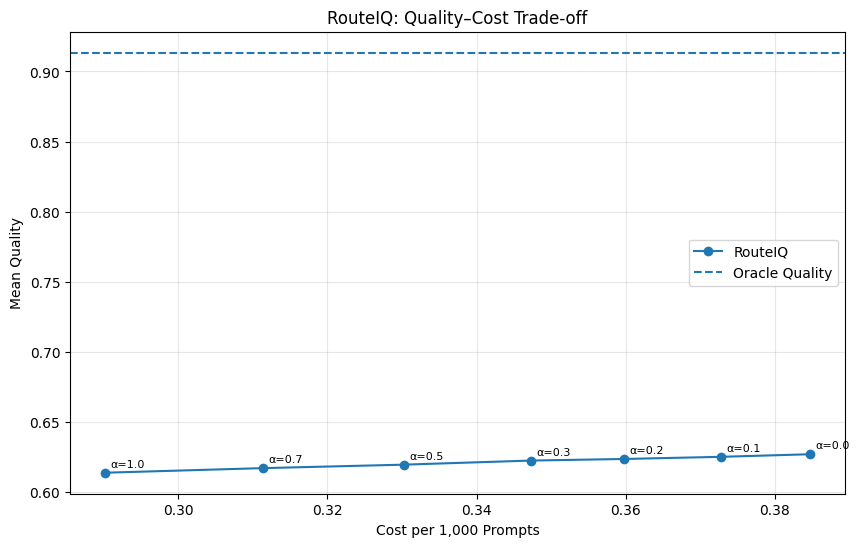

In [40]:

# Compare the quality and cost of each routing policy.
plt.figure(figsize=(10, 6))
plt.plot(results_df["Cost per 1000 Prompts"], results_df["Router Quality"], marker="o", label="RouteIQ")
plt.axhline(results_df["Oracle Quality"].iloc[0], linestyle="--", label="Oracle Quality")

for _, row in results_df.iterrows():
    plt.annotate(f"α={row['Alpha']}", (row["Cost per 1000 Prompts"], row["Router Quality"]), fontsize=8, xytext=(4, 4), textcoords="offset points")

plt.xlabel("Cost per 1,000 Prompts")
plt.ylabel("Mean Quality")
plt.title("RouteIQ: Quality–Cost Trade-off")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


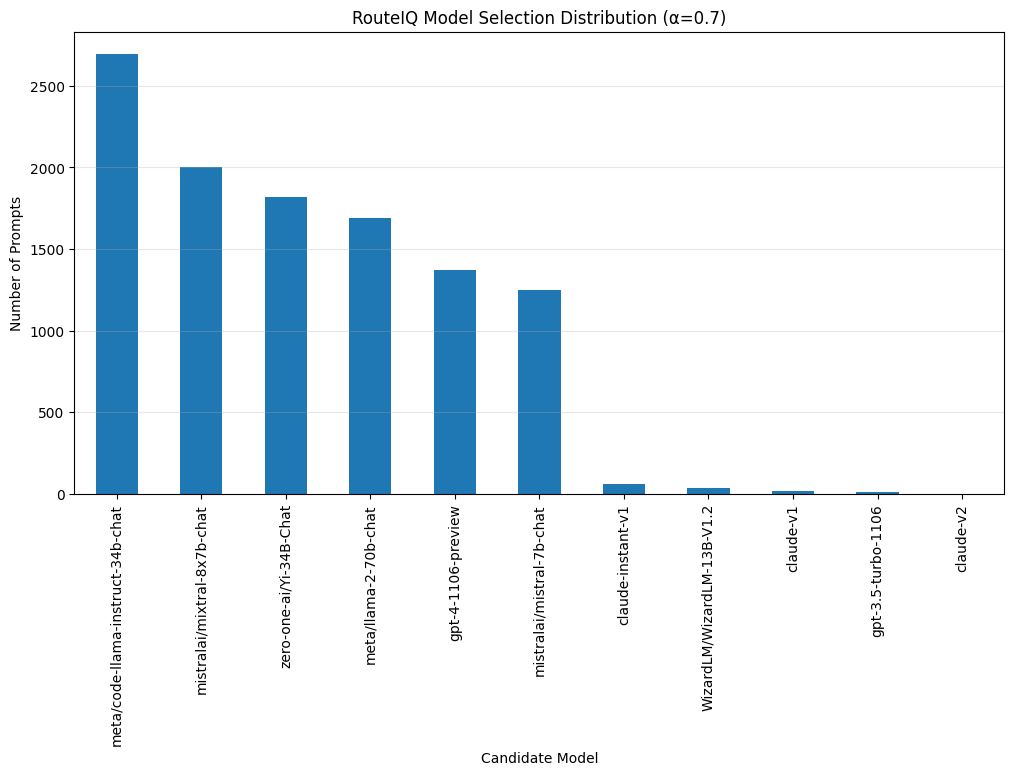

Selection percentages:


,Selection %
meta/code-llama-instruct-34b-chat,24.63
mistralai/mixtral-8x7b-chat,18.28
zero-one-ai/Yi-34B-Chat,16.61
meta/llama-2-70b-chat,15.44
gpt-4-1106-preview,12.54
mistralai/mistral-7b-chat,11.41
claude-instant-v1,0.54
WizardLM/WizardLM-13B-V1.2,0.30
claude-v1,0.14
gpt-3.5-turbo-1106,0.10


In [41]:

# Count the selected candidate models for the chosen alpha.
TARGET_ALPHA = 0.7
chosen_result = next(row for row in evaluation_results if row["Alpha"] == TARGET_ALPHA)
selected_indices = chosen_result["Selected Indices"]
selection_counts = pd.Series(selected_indices).value_counts().reindex(range(len(models)), fill_value=0)
selection_distribution = pd.Series(selection_counts.to_numpy(), index=models).sort_values(ascending=False)

plt.figure(figsize=(12, 6))
selection_distribution.plot(kind="bar")
plt.xlabel("Candidate Model")
plt.ylabel("Number of Prompts")
plt.title(f"RouteIQ Model Selection Distribution (α={TARGET_ALPHA})")
plt.xticks(rotation=90)
plt.grid(axis="y", alpha=0.3)
plt.show()

print("Selection percentages:")
display((selection_distribution / len(selected_indices) * 100).round(2).rename("Selection %").to_frame())


In [42]:

# Compare RouteIQ's selected model with oracle and GPT-4 benchmarks.
chosen_row = results_df.loc[results_df["Alpha"] == TARGET_ALPHA].iloc[0]
gpt4_row = baseline_df.loc[baseline_df["Model"] == "gpt-4-1106-preview"]

comparison = pd.DataFrame([
    {"Strategy": "RouteIQ", "Mean Quality": chosen_row["Router Quality"], "Cost per 1000 Prompts": chosen_row["Cost per 1000 Prompts"]},
    {"Strategy": "Oracle", "Mean Quality": chosen_row["Oracle Quality"], "Cost per 1000 Prompts": np.nan},
])

if not gpt4_row.empty:
    comparison.loc[len(comparison)] = {"Strategy": "GPT-4 (fixed)", "Mean Quality": gpt4_row.iloc[0]["Mean Quality"], "Cost per 1000 Prompts": gpt4_row.iloc[0]["Mean Cost"] * 1000}

display(comparison.round(4))
print(f"Quality regret at alpha={TARGET_ALPHA}: {chosen_row['Quality Regret']:.4f}")
if not gpt4_row.empty and gpt4_row.iloc[0]["Mean Cost"] > 0:
    savings = (1 - chosen_row["Cost per 1000 Prompts"] / (gpt4_row.iloc[0]["Mean Cost"] * 1000)) * 100
    print(f"Cost savings versus fixed GPT-4: {savings:.2f}%")


,Strategy,Mean Quality,Cost per 1000 Prompts
0,RouteIQ,0.6172,0.3114
1,Oracle,0.9134,NaN
2,GPT-4 (fixed),0.7819,3.2683


Quality regret at alpha=0.7: 0.2962
Cost savings versus fixed GPT-4: 90.47%


# RouteIQ: Results, Discussion and Key Achievements

## 1. Overall Results

RouteIQ was evaluated on 10,950 test prompts using 11 candidate language models. The Residual MLP predicts candidate-model suitability, while a cost-aware routing policy balances predicted suitability against recorded model costs.

The current evaluation produced the following results at \(\alpha = 0.7\):

| Metric | Result |
|---|---:|
| Test prompts evaluated | 10,950 |
| Candidate models | 11 |
| RouteIQ mean quality | 0.6172 |
| Oracle mean quality | 0.9134 |
| GPT-4 fixed-model mean quality | 0.7819 |
| RouteIQ cost per 1,000 prompts | 0.3114 cost units |
| GPT-4 cost per 1,000 prompts | 3.2683 cost units |
| Cost savings vs GPT-4 | 90.47% |
| Quality regret vs oracle | 0.2962 |

The results demonstrate a substantial reduction in recorded benchmark costs compared with using GPT-4 for every prompt. However, the router also achieves lower mean quality than the fixed GPT-4 baseline. Therefore, the current implementation demonstrates promising cost optimisation, but its quality-selection performance needs improvement before it can be considered a strong general-purpose routing system.

*Note: Cost units follow the supplied RouterBench data. These are benchmark estimates, not verified current provider prices or complete production costs.*

## 2. Quality–Cost Trade-off

The alpha experiment demonstrates a clear trade-off between quality and cost.

- At \(\alpha=0.0\), RouteIQ achieves a mean quality of 0.6271 with a cost of 0.3847 per 1,000 prompts.
- At \(\alpha=0.7\), mean quality decreases to 0.6172, while cost decreases to 0.3114.
- At \(\alpha=1.0\), mean quality decreases to 0.6139, while cost falls to 0.2902.

Increasing alpha from 0.0 to 1.0 reduces the reported cost by approximately 24.6%, with a quality reduction of 0.0132.

This indicates that the cost penalty has a measurable effect on routing decisions. However, alpha should be selected using validation data according to an explicit quality constraint or cost objective, rather than choosing the setting with the largest apparent savings on the test set.

## 3. Comparison with Individual Models

GPT-4-1106-preview achieves the highest mean quality among the individual candidate models, at 0.7819, with an average recorded cost of 0.003268 per prompt.

RouteIQ's mean quality at \(\alpha=0.7\) is 0.6172. Its quality is therefore approximately 0.1647 lower than the fixed GPT-4 baseline.

Despite this quality gap, the routing policy reduces recorded cost by approximately 90.47% relative to the fixed GPT-4 baseline.

This comparison highlights both the main benefit and the main limitation of the current system:

- **Benefit:** substantially lower benchmark cost.
- **Limitation:** a meaningful reduction in mean quality compared with always selecting GPT-4.

Consequently, RouteIQ should not yet be described as preserving GPT-4-level quality. Its next improvement should focus on better suitability prediction and stronger quality-aware routing constraints.

## 4. Oracle Comparison and Quality Regret

The oracle achieves a mean quality of 0.9134, compared with RouteIQ's 0.6172 at \(\alpha=0.7\).

The absolute quality regret is:

\[
0.9134 - 0.6172 = 0.2962
\]

This gap indicates that RouteIQ does not consistently identify the candidate models that produce the strongest recorded outcomes for each prompt.

The oracle is an upper-bound reference because it uses the observed outcomes to choose the best candidate per prompt. It is not a deployable baseline. The gap should therefore be interpreted as an indication of the remaining opportunity for improvement, rather than a direct comparison against a practical system.

## 5. Model Selection Distribution

At \(\alpha=0.7\), the routing policy selects several inexpensive candidates frequently:

| Candidate model | Selection percentage |
|---|---:|
| Code Llama Instruct 34B | 24.63% |
| Mixtral-8x7B-Chat | 18.28% |
| Yi-34B-Chat | 16.61% |
| Llama-2-70B-Chat | 15.44% |
| GPT-4-1106-preview | 12.54% |
| Mistral-7B-Chat | 11.41% |

The remaining candidates account for less than 1% each, according to the supplied distribution.

This shows that RouteIQ does not simply select GPT-4 for every prompt. It distributes requests across multiple candidate models, potentially allowing less expensive models to handle a substantial share of the workload.

However, frequent selection does not prove that a candidate is suitable for those prompts. In particular, Code Llama Instruct 34B has the lowest mean quality in the supplied individual-model comparison, yet it receives the largest share of routing decisions. This is an important diagnostic finding: the router's predicted suitability scores may not be sufficiently aligned with actual candidate quality.

Investigating score calibration, class weighting, label construction and the cost-penalty scale is therefore a priority.

## 6. Key Advantages and Achievements

### 6.1 Cost-aware routing

RouteIQ incorporates model cost directly into the selection policy rather than relying exclusively on predicted suitability. The experiments demonstrate that increasing the cost penalty can reduce recorded expenditure.

### 6.2 Multiple candidate models

The system considers 11 candidate models instead of relying on a single fixed provider or model. This creates the opportunity to distribute requests according to their predicted suitability and cost.

### 6.3 Learned suitability prediction

The Residual MLP learns from prompt embeddings and historical model-quality labels. This provides a trainable routing approach that can be compared against simpler methods such as k-nearest neighbours and fixed-model baselines.

### 6.4 Efficient prompt representation

Sentence-BERT converts prompts into 384-dimensional embeddings. These compact representations provide a practical input for the routing network without requiring the router itself to generate a full natural-language response.

### 6.5 Configurable cost–quality policy

The alpha parameter provides a straightforward way to investigate different cost–quality trade-offs. It can support policies designed around a maximum budget or minimum acceptable quality once those constraints are properly defined and validated.

### 6.6 Reproducible evaluation potential

The separation of preprocessing, model training, routing-policy evaluation and deployment makes it possible to save model artefacts, reproduce experiments and compare alternative routers using a consistent evaluation pipeline.

## 7. Limitations and Areas for Improvement

The current results also reveal important limitations.

- **Quality gap:** RouteIQ's mean quality of 0.6172 is below the fixed GPT-4 baseline of 0.7819.
- **Large oracle regret:** the absolute regret of 0.2962 indicates substantial room for improvement.
- **Potential prediction misalignment:** some low-quality candidates are selected frequently, suggesting that predicted suitability may not reflect actual outcomes reliably.
- **Calibration not yet established:** sigmoid outputs should not automatically be interpreted as calibrated probabilities of achieving the best quality.
- **Baseline comparisons remain important:** kNN, simple cost-based policies and relevant published RouterBench routers should be evaluated under the same splits and cost conventions.
- **Generalisation remains to be tested:** leave-one-task-out evaluation can reveal whether performance drops on unseen task categories.
- **Benchmark-to-production gap:** recorded benchmark costs do not include all possible production expenses, such as embedding inference, network overhead, retries and provider-specific failures.
- **Live evaluation remains valuable:** a small real-API experiment can test whether benchmark findings translate into actual latency, cost and response-quality behaviour.

## 8. Final Conclusion

RouteIQ establishes an experimental framework for cost-aware LLM routing using Sentence-BERT embeddings, a PyTorch Residual MLP and a configurable cost penalty. The current benchmark results demonstrate that the policy can reduce recorded costs substantially compared with fixed GPT-4 usage.

However, the quality reduction and large oracle regret show that cost savings alone are not sufficient to establish effective routing. The model-selection distribution also reveals potential weaknesses in how predicted suitability aligns with recorded quality.

The most important next steps are to validate alpha selection using validation data, compare the Residual MLP against kNN and published routing baselines, assess calibration and leave-one-task-out generalisation, and reproduce the final results under a consistent evaluation protocol.

**Overall assessment:** RouteIQ demonstrates a promising cost-optimisation approach, with meaningful savings in the current benchmark experiment, but its routing quality and generalisation require further validation before claiming production readiness.